In [ ]:
!pip install einops scikit-image torchvision matplotlib seaborn pandas

import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")


PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
import os, zipfile

EXTRACT_PATH = "/content/HDC2021"
os.makedirs(EXTRACT_PATH, exist_ok=True)

# Direct download links from Zenodo (Helsinki Deblur Challenge 2021)
# Go to https://zenodo.org/records/5713637 and copy the download links
# They look like: https://zenodo.org/records/5713637/files/filename.zip

zip_urls = [
    "https://zenodo.org/records/5713637/files/steps_0_to_4.zip",
    "https://zenodo.org/records/5713637/files/steps_5_to_9.zip",
    "https://zenodo.org/records/5713637/files/steps_10_to_14.zip",
    "https://zenodo.org/records/5713637/files/steps_15_to_19.zip",
]

for url in zip_urls:
    filename = url.split("/")[-1]
    filepath = os.path.join("/content", filename)

    if not os.path.exists(filepath):
        print(f"⬇️ Downloading {filename}...")
        !wget -q --show-progress -O "{filepath}" "{url}"

    print(f"📦 Extracting {filename}...")
    with zipfile.ZipFile(filepath, 'r') as z:
        z.extractall(EXTRACT_PATH)

    # Remove ZIP to save disk space
    os.remove(filepath)
    print(f"  ✅ {filename} done!\n")

print(f"✅ All steps extracted!")
print(f"Contents: {sorted(os.listdir(EXTRACT_PATH))}")


⬇️ Downloading steps_0_to_4.zip...
/content/steps_0_to 100%[===================>]   2.84G  18.8MB/s    in 2m 34s  
📦 Extracting steps_0_to_4.zip...
  ✅ steps_0_to_4.zip done!

⬇️ Downloading steps_5_to_9.zip...
/content/steps_5_to 100%[===================>]   2.79G  13.1MB/s    in 3m 48s  
📦 Extracting steps_5_to_9.zip...
  ✅ steps_5_to_9.zip done!

⬇️ Downloading steps_10_to_14.zip...
/content/steps_10_t 100%[===================>]   3.39G  12.7MB/s    in 6m 37s  
📦 Extracting steps_10_to_14.zip...
  ✅ steps_10_to_14.zip done!

⬇️ Downloading steps_15_to_19.zip...
/content/steps_15_t 100%[===================>]   3.34G  12.6MB/s    in 4m 38s  
📦 Extracting steps_15_to_19.zip...
  ✅ steps_15_to_19.zip done!

✅ All steps extracted!
Contents: ['__MACOSX', 'steps_0_to_4', 'steps_10_to_14', 'steps_15_to_19', 'steps_5_to_9']


In [ ]:
import os
import glob
import re

BASE = "/content/HDC2021"
blur_levels = {}

# Go through each step folder
for step_folder in sorted(os.listdir(BASE)):
    if step_folder.startswith("__") or step_folder.startswith("."):
        continue  # Skip __MACOSX and .DS_Store

    step_path = os.path.join(BASE, step_folder)
    if not os.path.isdir(step_path):
        continue

    focused_dir = os.path.join(step_path, "CAM01_focused")
    blurred_dir = os.path.join(step_path, "CAM02_blurred")

    if not os.path.exists(focused_dir) or not os.path.exists(blurred_dir):
        continue

    # Get all .tif images
    focused_imgs = sorted(glob.glob(os.path.join(focused_dir, "*.tif")))
    blurred_imgs = sorted(glob.glob(os.path.join(blurred_dir, "*.tif")))

    # Group by step number from filename (e.g., focusStep_0_... → step_0)
    step_groups = {}
    for fimg in focused_imgs:
        fname = os.path.basename(fimg)
        match = re.search(r'focusStep_(\d+)_', fname)
        if match:
            step_num = match.group(1)
            if step_num not in step_groups:
                step_groups[step_num] = {'focused': [], 'blurred': []}
            step_groups[step_num]['focused'].append(fimg)

    for bimg in blurred_imgs:
        fname = os.path.basename(bimg)
        match = re.search(r'focusStep_(\d+)_', fname)
        if match:
            step_num = match.group(1)
            if step_num not in step_groups:
                step_groups[step_num] = {'focused': [], 'blurred': []}
            step_groups[step_num]['blurred'].append(bimg)

    # Add to blur_levels
    for step_num, imgs in step_groups.items():
        level_name = f"step_{step_num}"
        if imgs['focused'] and imgs['blurred']:
            blur_levels[level_name] = {
                'focused': sorted(imgs['focused']),
                'blurred': sorted(imgs['blurred']),
                'count': min(len(imgs['focused']), len(imgs['blurred']))
            }

# Sort by step number
blur_levels = dict(sorted(blur_levels.items(), key=lambda x: int(x[0].split('_')[1])))

print(f"\n✅ Found {len(blur_levels)} blur levels:")
total_images = 0
for level, data in blur_levels.items():
    print(f"  {level}: {data['count']} image pairs")
    total_images += data['count']
print(f"\n📊 Total image pairs across all levels: {total_images}")



✅ Found 20 blur levels:
  step_0: 59 image pairs
  step_1: 59 image pairs
  step_2: 59 image pairs
  step_3: 59 image pairs
  step_4: 59 image pairs
  step_5: 59 image pairs
  step_6: 59 image pairs
  step_7: 59 image pairs
  step_8: 59 image pairs
  step_9: 59 image pairs
  step_10: 59 image pairs
  step_11: 59 image pairs
  step_12: 59 image pairs
  step_13: 59 image pairs
  step_14: 59 image pairs
  step_15: 59 image pairs
  step_16: 59 image pairs
  step_17: 59 image pairs
  step_18: 59 image pairs
  step_19: 59 image pairs

📊 Total image pairs across all levels: 1180


In [ ]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

class HDCDeblurDataset(Dataset):
    """Helsinki Deblur Challenge Dataset for Restormer Training."""

    def __init__(self, blur_levels_dict, patch_size=128, levels_to_use=None):
        """
        Args:
            blur_levels_dict: Dictionary from Cell 3
            patch_size: Size of random crops for training
            levels_to_use: List of specific levels to use (None = all)
        """
        self.patch_size = patch_size
        self.pairs = []

        for level_name, data in blur_levels_dict.items():
            if levels_to_use and level_name not in levels_to_use:
                continue
            for i in range(data['count']):
                self.pairs.append({
                    'blurred': data['blurred'][i],
                    'focused': data['focused'][i],
                    'level': level_name
                })

        self.transform = transforms.Compose([
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]

        # Load images
        blurred = cv2.imread(pair['blurred'])
        focused = cv2.imread(pair['focused'])

        if blurred is None or focused is None:
            # Fallback: return a random valid pair
            return self.__getitem__((idx + 1) % len(self))

        # Convert BGR to RGB
        blurred = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)
        focused = cv2.cvtColor(focused, cv2.COLOR_BGR2RGB)

        # Resize to same dimensions if needed
        h = min(blurred.shape[0], focused.shape[0])
        w = min(blurred.shape[1], focused.shape[1])
        blurred = cv2.resize(blurred, (w, h))
        focused = cv2.resize(focused, (w, h))

        # Random crop
        if h > self.patch_size and w > self.patch_size:
            top = np.random.randint(0, h - self.patch_size)
            left = np.random.randint(0, w - self.patch_size)
            blurred = blurred[top:top+self.patch_size, left:left+self.patch_size]
            focused = focused[top:top+self.patch_size, left:left+self.patch_size]
        else:
            blurred = cv2.resize(blurred, (self.patch_size, self.patch_size))
            focused = cv2.resize(focused, (self.patch_size, self.patch_size))

        # Convert to tensors
        blurred_tensor = self.transform(blurred)
        focused_tensor = self.transform(focused)

        return blurred_tensor, focused_tensor

# ── Create Dataset ──
dataset = HDCDeblurDataset(blur_levels, patch_size=128)

# ── Train/Test Split (80/20) ──
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size],
                                            generator=torch.Generator().manual_seed(42))

# ── DataLoaders ──
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print(f"✅ Dataset Ready!")
print(f"   Total pairs:    {len(dataset)}")
print(f"   Training images: {train_size}")
print(f"   Testing images:  {test_size}")
print(f"   Batch size:      4")
print(f"   Patch size:      128×128")


✅ Dataset Ready!
   Total pairs:    1180
   Training images: 944
   Testing images:  236
   Batch size:      4
   Patch size:      128×128


In [ ]:
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from einops import rearrange
import numbers

# ── Utility Layers ──
class BiasFree_LayerNorm(nn.Module):
    def __init__(self, normalized_shape):
        super().__init__()
        if isinstance(normalized_shape, numbers.Integral):
            normalized_shape = (normalized_shape,)
        self.weight = nn.Parameter(torch.ones(normalized_shape))
        self.normalized_shape = normalized_shape

    def forward(self, x):
        sigma = x.var(-1, keepdim=True, unbiased=False)
        return x / torch.sqrt(sigma + 1e-5) * self.weight

class LayerNorm(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.body = BiasFree_LayerNorm(dim)

    def forward(self, x):
        h, w = x.shape[-2:]
        return self.body(rearrange(x, "b c h w -> b (h w) c")).reshape(x.shape[0], x.shape[1], h, w)

# ── MDTA (Multi-DConv Head Transposed Attention) ──
class MDTA(nn.Module):
    def __init__(self, dim, num_heads, bias=False):
        super().__init__()
        self.num_heads = num_heads
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))
        self.qkv = nn.Conv2d(dim, dim * 3, kernel_size=1, bias=bias)
        self.qkv_dwconv = nn.Conv2d(dim * 3, dim * 3, kernel_size=3, stride=1, padding=1, groups=dim * 3, bias=bias)
        self.project_out = nn.Conv2d(dim, dim, kernel_size=1, bias=bias)

    def forward(self, x):
        b, c, h, w = x.shape
        qkv = self.qkv_dwconv(self.qkv(x))
        q, k, v = qkv.chunk(3, dim=1)
        q = rearrange(q, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        k = rearrange(k, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        v = rearrange(v, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        q = F.normalize(q, dim=-1)
        k = F.normalize(k, dim=-1)
        attn = (q @ k.transpose(-2, -1)) * self.temperature
        attn = attn.softmax(dim=-1)
        out = attn @ v
        out = rearrange(out, "b head c (h w) -> b (head c) h w", head=self.num_heads, h=h, w=w)
        return self.project_out(out)

# ── GDFN (Gated-Dconv Feed-Forward Network) ──
class GDFN(nn.Module):
    def __init__(self, dim, ffn_expansion=2.66, bias=False):
        super().__init__()
        hidden_features = int(dim * ffn_expansion)
        self.project_in = nn.Conv2d(dim, hidden_features * 2, kernel_size=1, bias=bias)
        self.dwconv = nn.Conv2d(hidden_features * 2, hidden_features * 2, kernel_size=3, stride=1, padding=1, groups=hidden_features * 2, bias=bias)
        self.project_out = nn.Conv2d(hidden_features, dim, kernel_size=1, bias=bias)

    def forward(self, x):
        x = self.project_in(x)
        x1, x2 = self.dwconv(x).chunk(2, dim=1)
        x = F.gelu(x1) * x2
        return self.project_out(x)

# ── Transformer Block ──
class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, ffn_expansion=2.66, bias=False):
        super().__init__()
        self.norm1 = LayerNorm(dim)
        self.attn = MDTA(dim, num_heads, bias)
        self.norm2 = LayerNorm(dim)
        self.ffn = GDFN(dim, ffn_expansion, bias)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

# ── Down/Upsample ──
class Downsample(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(n_feat, n_feat // 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.PixelUnshuffle(2))

    def forward(self, x):
        return self.body(x)

class Upsample(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(n_feat, n_feat * 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.PixelShuffle(2))

    def forward(self, x):
        return self.body(x)

# ── Full Restormer ──
class Restormer(nn.Module):
    def __init__(self, inp_channels=3, out_channels=3, dim=48,
                 num_blocks=[4, 6, 6, 8], num_refinement_blocks=4,
                 heads=[1, 2, 4, 8], ffn_expansion=2.66, bias=False):
        super().__init__()
        self.patch_embed = nn.Conv2d(inp_channels, dim, kernel_size=3, padding=1, bias=bias)

        # Encoder
        self.encoder_level1 = nn.Sequential(*[TransformerBlock(dim, heads[0], ffn_expansion, bias) for _ in range(num_blocks[0])])
        self.down1_2 = Downsample(dim)
        self.encoder_level2 = nn.Sequential(*[TransformerBlock(int(dim*2**1), heads[1], ffn_expansion, bias) for _ in range(num_blocks[1])])
        self.down2_3 = Downsample(int(dim*2**1))
        self.encoder_level3 = nn.Sequential(*[TransformerBlock(int(dim*2**2), heads[2], ffn_expansion, bias) for _ in range(num_blocks[2])])
        self.down3_4 = Downsample(int(dim*2**2))

        # Bottleneck
        self.latent = nn.Sequential(*[TransformerBlock(int(dim*2**3), heads[3], ffn_expansion, bias) for _ in range(num_blocks[3])])

        # Decoder
        self.up4_3 = Upsample(int(dim*2**3))
        self.reduce_chan_level3 = nn.Conv2d(int(dim*2**3), int(dim*2**2), kernel_size=1, bias=bias)
        self.decoder_level3 = nn.Sequential(*[TransformerBlock(int(dim*2**2), heads[2], ffn_expansion, bias) for _ in range(num_blocks[2])])
        self.up3_2 = Upsample(int(dim*2**2))
        self.reduce_chan_level2 = nn.Conv2d(int(dim*2**2), int(dim*2**1), kernel_size=1, bias=bias)
        self.decoder_level2 = nn.Sequential(*[TransformerBlock(int(dim*2**1), heads[1], ffn_expansion, bias) for _ in range(num_blocks[1])])
        self.up2_1 = Upsample(int(dim*2**1))
        self.decoder_level1 = nn.Sequential(*[TransformerBlock(int(dim*2**1), heads[0], ffn_expansion, bias) for _ in range(num_blocks[0])])

        # Refinement
        self.refinement = nn.Sequential(*[TransformerBlock(int(dim*2**1), heads[0], ffn_expansion, bias) for _ in range(num_refinement_blocks)])
        self.output = nn.Conv2d(int(dim*2**1), out_channels, kernel_size=3, padding=1, bias=bias)

    def forward(self, inp_img):
        inp_enc_level1 = self.patch_embed(inp_img)
        out_enc_level1 = self.encoder_level1(inp_enc_level1)
        inp_enc_level2 = self.down1_2(out_enc_level1)
        out_enc_level2 = self.encoder_level2(inp_enc_level2)
        inp_enc_level3 = self.down2_3(out_enc_level2)
        out_enc_level3 = self.encoder_level3(inp_enc_level3)
        inp_enc_level4 = self.down3_4(out_enc_level3)
        latent = self.latent(inp_enc_level4)
        inp_dec_level3 = self.up4_3(latent)
        inp_dec_level3 = torch.cat([inp_dec_level3, out_enc_level3], dim=1)
        inp_dec_level3 = self.reduce_chan_level3(inp_dec_level3)
        out_dec_level3 = self.decoder_level3(inp_dec_level3)
        inp_dec_level2 = self.up3_2(out_dec_level3)
        inp_dec_level2 = torch.cat([inp_dec_level2, out_enc_level2], dim=1)
        inp_dec_level2 = self.reduce_chan_level2(inp_dec_level2)
        out_dec_level2 = self.decoder_level2(inp_dec_level2)
        inp_dec_level1 = self.up2_1(out_dec_level2)
        inp_dec_level1 = torch.cat([inp_dec_level1, out_enc_level1], dim=1)
        out_dec_level1 = self.decoder_level1(inp_dec_level1)
        out_dec_level1 = self.refinement(out_dec_level1)
        output = self.output(out_dec_level1) + inp_img
        return output

# ── Instantiate Model ──
# Using a LIGHTER config for Colab GPU (reduced dim=16, fewer blocks)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Restormer(
    inp_channels=3, out_channels=3,
    dim=16,                          # Reduced from 48 for Colab speed
    num_blocks=[2, 2, 2, 2],         # Reduced from [4,6,6,8]
    num_refinement_blocks=2,         # Reduced from 4
    heads=[1, 2, 4, 8],
    ffn_expansion=2.66,
    bias=False,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"✅ Restormer loaded on {device}")
print(f"   Total parameters: {n_params:,}")


✅ Restormer loaded on cuda
   Total parameters: 1,176,694


In [ ]:
print("=" * 60)
print("         RESTORMER ARCHITECTURE SUMMARY")
print("=" * 60)
print(f"""
┌─────────────────────────────────────────────────┐
│              RESTORMER (Ours)                    │
│   Efficient Transformer for Image Restoration   │
├─────────────────────────────────────────────────┤
│                                                 │
│  Input Image (3, H, W)                          │
│       │                                         │
│  ┌────▼────┐                                    │
│  │Patch Embed│ Conv2d(3 → 16)                   │
│  └────┬────┘                                    │
│       │                                         │
│  ╔════╧════════════════════════════════════╗     │
│  ║         ENCODER                         ║    │
│  ║  Level 1: 2× TransformerBlock (dim=16)  ║    │
│  ║     │ Downsample (PixelUnshuffle)       ║    │
│  ║  Level 2: 2× TransformerBlock (dim=32)  ║    │
│  ║     │ Downsample                        ║    │
│  ║  Level 3: 2× TransformerBlock (dim=64)  ║    │
│  ║     │ Downsample                        ║    │
│  ╚════╤════════════════════════════════════╝     │
│       │                                         │
│  ┌────▼──────────────────────┐                  │
│  │  BOTTLENECK               │                  │
│  │  2× TransformerBlock      │                  │
│  │  (dim=128, heads=8)       │                  │
│  └────┬──────────────────────┘                  │
│       │                                         │
│  ╔════╧════════════════════════════════════╗     │
│  ║         DECODER (+ Skip Connections)    ║    │
│  ║  Level 3: Upsample + Cat + 2× TBlock   ║    │
│  ║  Level 2: Upsample + Cat + 2× TBlock   ║    │
│  ║  Level 1: Upsample + Cat + 2× TBlock   ║    │
│  ╚════╤════════════════════════════════════╝     │
│       │                                         │
│  ┌────▼────┐                                    │
│  │Refinement│ 2× TransformerBlock               │
│  └────┬────┘                                    │
│       │                                         │
│  ┌────▼────┐                                    │
│  │ Output  │ Conv2d(32 → 3) + Residual          │
│  └────┬────┘                                    │
│       │                                         │
│  Restored Image (3, H, W)                       │
└─────────────────────────────────────────────────┘

TransformerBlock = LayerNorm → MDTA → Residual → LayerNorm → GDFN → Residual

  MDTA: Multi-DConv Head Transposed Attention
        (Channel attention instead of spatial → O(C²) not O(N²))

  GDFN: Gated-Dconv Feed-Forward Network
        (Gating mechanism with depth-wise convolution)
""")

print(f"Total Parameters:       {n_params:,}")
print(f"Base Dimension:         16")
print(f"Encoder Blocks:         [2, 2, 2, 2]")
print(f"Attention Heads:        [1, 2, 4, 8]")
print(f"FFN Expansion:          2.66")
print(f"Refinement Blocks:      2")
print("=" * 60)


         RESTORMER ARCHITECTURE SUMMARY

┌─────────────────────────────────────────────────┐
│              RESTORMER (Ours)                    │
│   Efficient Transformer for Image Restoration   │
├─────────────────────────────────────────────────┤
│                                                 │
│  Input Image (3, H, W)                          │
│       │                                         │
│  ┌────▼────┐                                    │
│  │Patch Embed│ Conv2d(3 → 16)                   │
│  └────┬────┘                                    │
│       │                                         │
│  ╔════╧════════════════════════════════════╗     │
│  ║         ENCODER                         ║    │
│  ║  Level 1: 2× TransformerBlock (dim=16)  ║    │
│  ║     │ Downsample (PixelUnshuffle)       ║    │
│  ║  Level 2: 2× TransformerBlock (dim=32)  ║    │
│  ║     │ Downsample                        ║    │
│  ║  Level 3: 2× TransformerBlock (dim=64)  ║    │
│  ║     │ Downsample

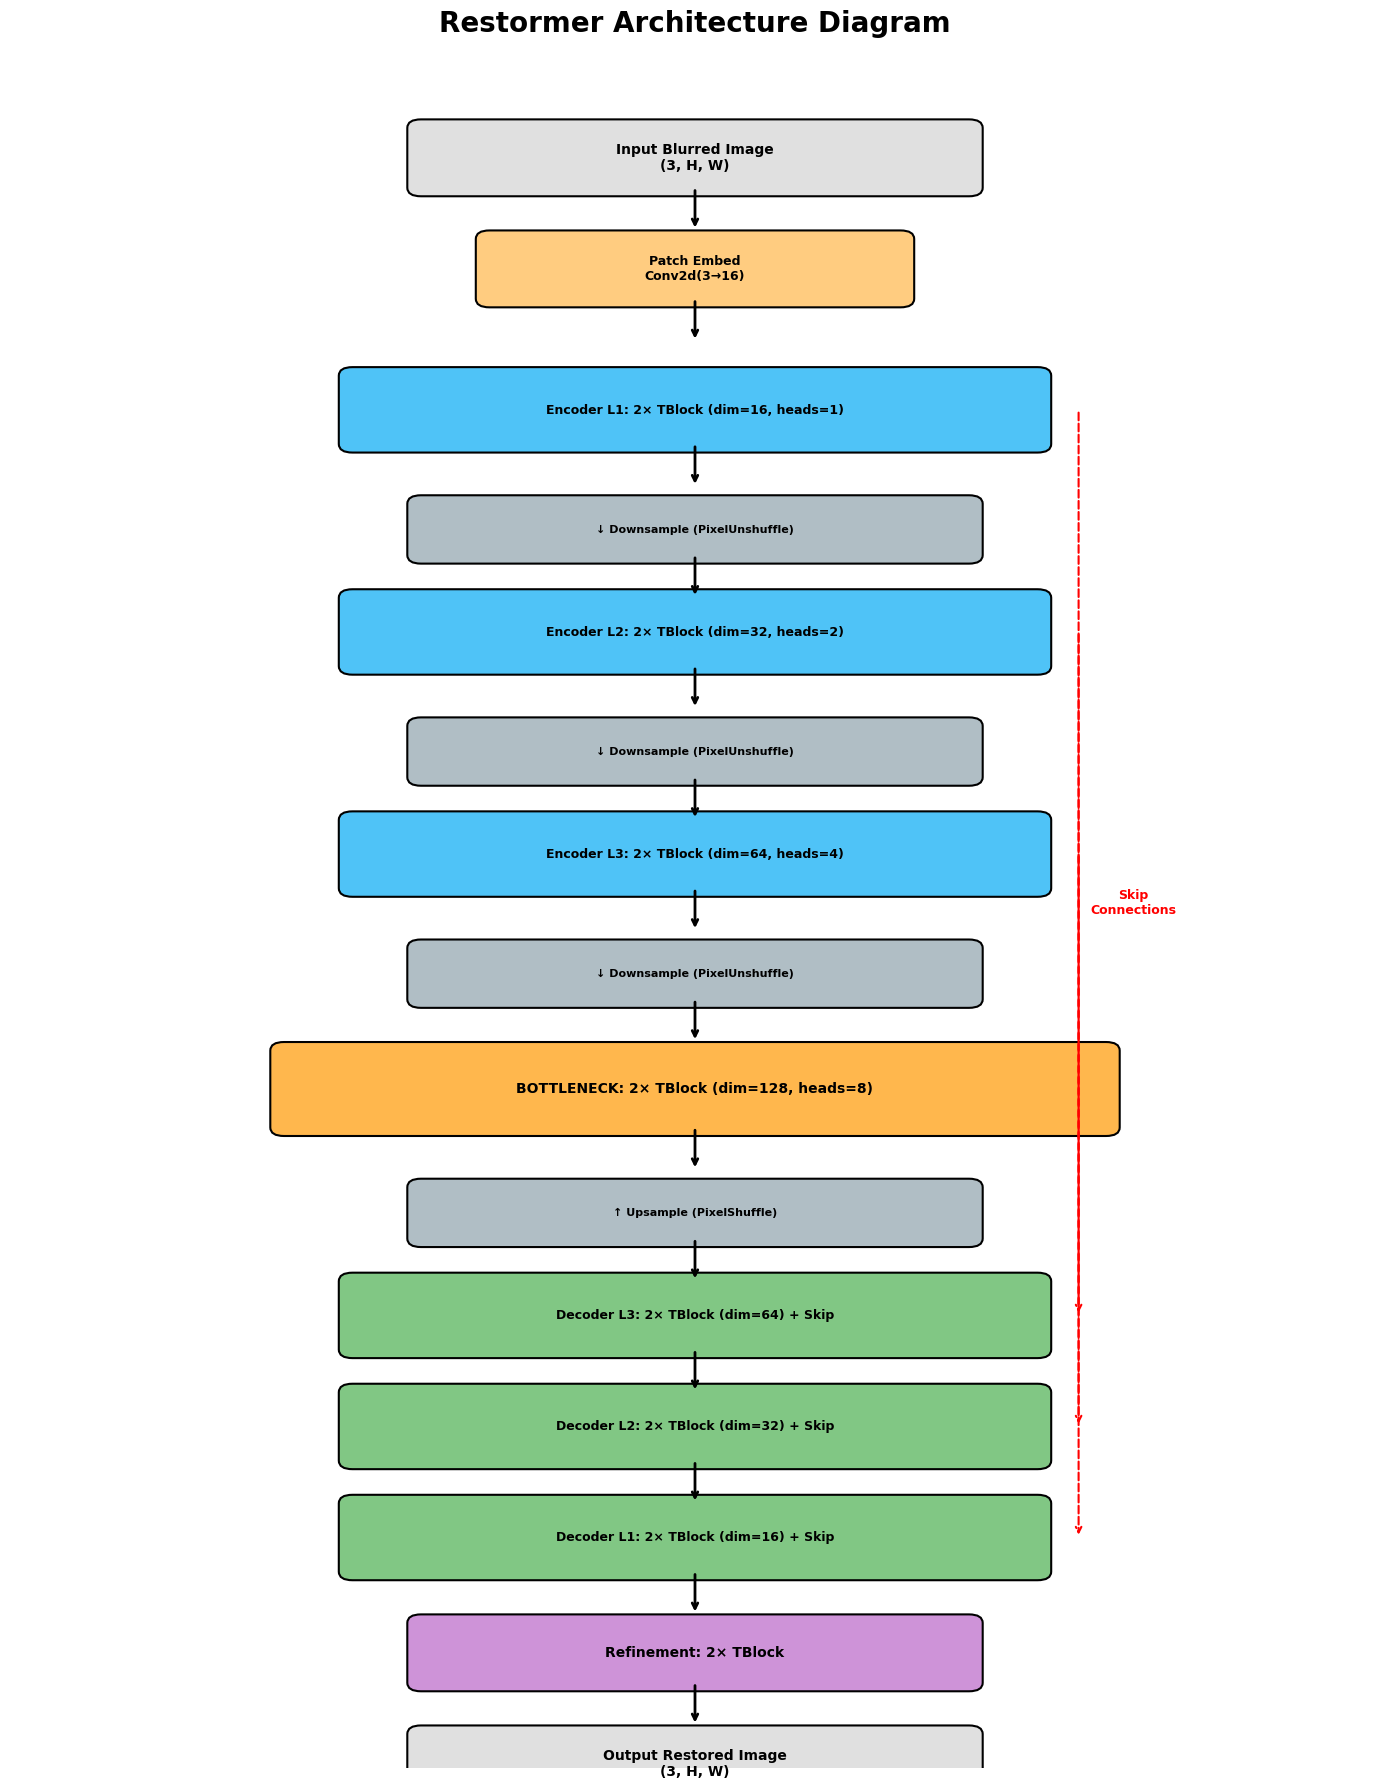

✅ Architecture diagram saved as 'restormer_architecture.png'


In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(1, 1, figsize=(14, 18))
ax.set_xlim(0, 10)
ax.set_ylim(0, 20)
ax.axis('off')
ax.set_title("Restormer Architecture Diagram", fontsize=20, fontweight='bold', pad=20)

# Colors
enc_color = '#4FC3F7'   # Light Blue
dec_color = '#81C784'   # Light Green
bot_color = '#FFB74D'   # Orange
ref_color = '#CE93D8'   # Purple
io_color  = '#E0E0E0'   # Gray

def draw_block(ax, x, y, w, h, text, color, fontsize=9):
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1",
                                    facecolor=color, edgecolor='black', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold')

# Input
draw_block(ax, 3, 18.5, 4, 0.7, "Input Blurred Image\n(3, H, W)", io_color, 10)
ax.annotate('', xy=(5, 18.0), xytext=(5, 18.5), arrowprops=dict(arrowstyle='->', lw=2))

# Patch Embed
draw_block(ax, 3.5, 17.2, 3, 0.7, "Patch Embed\nConv2d(3→16)", '#FFCC80', 9)
ax.annotate('', xy=(5, 16.7), xytext=(5, 17.2), arrowprops=dict(arrowstyle='->', lw=2))

# Encoder
draw_block(ax, 2.5, 15.5, 5, 0.8, "Encoder L1: 2× TBlock (dim=16, heads=1)", enc_color)
ax.annotate('', xy=(5, 15.0), xytext=(5, 15.5), arrowprops=dict(arrowstyle='->', lw=2))
draw_block(ax, 3, 14.2, 4, 0.6, "↓ Downsample (PixelUnshuffle)", '#B0BEC5', 8)
ax.annotate('', xy=(5, 13.7), xytext=(5, 14.2), arrowprops=dict(arrowstyle='->', lw=2))

draw_block(ax, 2.5, 12.9, 5, 0.8, "Encoder L2: 2× TBlock (dim=32, heads=2)", enc_color)
ax.annotate('', xy=(5, 12.4), xytext=(5, 12.9), arrowprops=dict(arrowstyle='->', lw=2))
draw_block(ax, 3, 11.6, 4, 0.6, "↓ Downsample (PixelUnshuffle)", '#B0BEC5', 8)
ax.annotate('', xy=(5, 11.1), xytext=(5, 11.6), arrowprops=dict(arrowstyle='->', lw=2))

draw_block(ax, 2.5, 10.3, 5, 0.8, "Encoder L3: 2× TBlock (dim=64, heads=4)", enc_color)
ax.annotate('', xy=(5, 9.8), xytext=(5, 10.3), arrowprops=dict(arrowstyle='->', lw=2))
draw_block(ax, 3, 9.0, 4, 0.6, "↓ Downsample (PixelUnshuffle)", '#B0BEC5', 8)
ax.annotate('', xy=(5, 8.5), xytext=(5, 9.0), arrowprops=dict(arrowstyle='->', lw=2))

# Bottleneck
draw_block(ax, 2, 7.5, 6, 0.9, "BOTTLENECK: 2× TBlock (dim=128, heads=8)", bot_color, 10)
ax.annotate('', xy=(5, 7.0), xytext=(5, 7.5), arrowprops=dict(arrowstyle='->', lw=2))

# Decoder
draw_block(ax, 3, 6.2, 4, 0.6, "↑ Upsample (PixelShuffle)", '#B0BEC5', 8)
ax.annotate('', xy=(5, 5.7), xytext=(5, 6.2), arrowprops=dict(arrowstyle='->', lw=2))
draw_block(ax, 2.5, 4.9, 5, 0.8, "Decoder L3: 2× TBlock (dim=64) + Skip", dec_color)
ax.annotate('', xy=(5, 4.4), xytext=(5, 4.9), arrowprops=dict(arrowstyle='->', lw=2))

draw_block(ax, 2.5, 3.6, 5, 0.8, "Decoder L2: 2× TBlock (dim=32) + Skip", dec_color)
ax.annotate('', xy=(5, 3.1), xytext=(5, 3.6), arrowprops=dict(arrowstyle='->', lw=2))

draw_block(ax, 2.5, 2.3, 5, 0.8, "Decoder L1: 2× TBlock (dim=16) + Skip", dec_color)
ax.annotate('', xy=(5, 1.8), xytext=(5, 2.3), arrowprops=dict(arrowstyle='->', lw=2))

# Refinement
draw_block(ax, 3, 1.0, 4, 0.7, "Refinement: 2× TBlock", ref_color, 10)
ax.annotate('', xy=(5, 0.5), xytext=(5, 1.0), arrowprops=dict(arrowstyle='->', lw=2))

# Output
draw_block(ax, 3, -0.3, 4, 0.7, "Output Restored Image\n(3, H, W)", io_color, 10)

# Skip connection arrows (right side)
for y_enc, y_dec in [(15.9, 2.7), (13.3, 4.0), (10.7, 5.3)]:
    ax.annotate('', xy=(7.8, y_dec), xytext=(7.8, y_enc),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='red', linestyle='dashed'))
ax.text(8.2, 10, "Skip\nConnections", fontsize=9, color='red', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig("restormer_architecture.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Architecture diagram saved as 'restormer_architecture.png'")


In [ ]:
import torch.optim as optim
from skimage.metrics import peak_signal_noise_ratio as calc_psnr
from skimage.metrics import structural_similarity as calc_ssim
import time

# ══════════════════════════════════════════
# HYPERPARAMETERS
# ══════════════════════════════════════════
NUM_EPOCHS = 120
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
SCHEDULER_STEP = 50          # Reduce LR every N epochs
SCHEDULER_GAMMA = 0.5        # LR multiplier
LOSS_FUNCTION = "L1"         # Charbonnier / L1 Loss

print("=" * 50)
print("         HYPERPARAMETERS")
print("=" * 50)
print(f"  Epochs:          {NUM_EPOCHS}")
print(f"  Learning Rate:   {LEARNING_RATE}")
print(f"  Weight Decay:    {WEIGHT_DECAY}")
print(f"  LR Scheduler:    StepLR (step={SCHEDULER_STEP}, gamma={SCHEDULER_GAMMA})")
print(f"  Loss Function:   {LOSS_FUNCTION} (Charbonnier)")
print(f"  Optimizer:        AdamW")
print(f"  Batch Size:       4")
print(f"  Patch Size:       128×128")
print(f"  Training Images:  {train_size}")
print(f"  Testing Images:   {test_size}")
print("=" * 50)

# ── Loss, Optimizer, Scheduler ──
class CharbonnierLoss(nn.Module):
    """Charbonnier Loss (robust version of L1)."""
    def __init__(self, eps=1e-3):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target):
        return torch.mean(torch.sqrt((pred - target) ** 2 + self.eps ** 2))

criterion = CharbonnierLoss().to(device)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=SCHEDULER_STEP, gamma=SCHEDULER_GAMMA)

# ── Training History ──
history = {
    'train_loss': [], 'val_loss': [],
    'val_psnr': [], 'val_ssim': [],
    'lr': []
}

# ══════════════════════════════════════════
# TRAINING LOOP
# ══════════════════════════════════════════
print("\n🚀 Starting Training...\n")
best_psnr = 0

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()

    # ── TRAIN ──
    model.train()
    train_loss = 0
    for batch_idx, (blurred, focused) in enumerate(train_loader):
        blurred, focused = blurred.to(device), focused.to(device)
        optimizer.zero_grad()
        restored = model(blurred)
        loss = criterion(restored, focused)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)

    # ── VALIDATE ──
    model.eval()
    val_loss = 0
    val_psnr_sum = 0
    val_ssim_sum = 0
    val_count = 0

    with torch.no_grad():
        for blurred, focused in test_loader:
            blurred, focused = blurred.to(device), focused.to(device)
            restored = model(blurred)
            val_loss += criterion(restored, focused).item()

            # Calculate PSNR & SSIM per image
            for i in range(restored.shape[0]):
                pred_np = restored[i].cpu().clamp(0, 1).permute(1, 2, 0).numpy()
                gt_np = focused[i].cpu().clamp(0, 1).permute(1, 2, 0).numpy()
                val_psnr_sum += calc_psnr(gt_np, pred_np, data_range=1.0)
                val_ssim_sum += calc_ssim(gt_np, pred_np, data_range=1.0, channel_axis=2)
                val_count += 1

    val_loss /= len(test_loader)
    avg_psnr = val_psnr_sum / max(val_count, 1)
    avg_ssim = val_ssim_sum / max(val_count, 1)

    # Save history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_psnr'].append(avg_psnr)
    history['val_ssim'].append(avg_ssim)
    history['lr'].append(optimizer.param_groups[0]['lr'])

    scheduler.step()

    elapsed = time.time() - start_time

    # Save best model
    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save(model.state_dict(), "best_restormer.pth")

    # Print progress every 5 epochs
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:3d}/{NUM_EPOCHS}] | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"PSNR: {avg_psnr:.2f} dB | SSIM: {avg_ssim:.4f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.6f} | "
              f"Time: {elapsed:.1f}s")

print(f"\n✅ Training Complete! Best PSNR: {best_psnr:.2f} dB")
print(f"   Best model saved as 'best_restormer.pth'")


         HYPERPARAMETERS
  Epochs:          120
  Learning Rate:   0.0002
  Weight Decay:    0.0001
  LR Scheduler:    StepLR (step=50, gamma=0.5)
  Loss Function:   L1 (Charbonnier)
  Optimizer:        AdamW
  Batch Size:       4
  Patch Size:       128×128
  Training Images:  944
  Testing Images:   236

🚀 Starting Training...

Epoch [  1/120] | Train Loss: 0.1106 | Val Loss: 0.1143 | PSNR: 19.33 dB | SSIM: 0.3577 | LR: 0.000200 | Time: 80.3s
Epoch [  5/120] | Train Loss: 0.1085 | Val Loss: 0.1032 | PSNR: 20.44 dB | SSIM: 0.3969 | LR: 0.000200 | Time: 78.6s
Epoch [ 10/120] | Train Loss: 0.1051 | Val Loss: 0.0959 | PSNR: 20.56 dB | SSIM: 0.4186 | LR: 0.000200 | Time: 75.9s
Epoch [ 15/120] | Train Loss: 0.1023 | Val Loss: 0.1120 | PSNR: 19.48 dB | SSIM: 0.4307 | LR: 0.000200 | Time: 75.2s
Epoch [ 20/120] | Train Loss: 0.0958 | Val Loss: 0.0999 | PSNR: 20.41 dB | SSIM: 0.4639 | LR: 0.000200 | Time: 73.7s
Epoch [ 25/120] | Train Loss: 0.0981 | Val Loss: 0.1005 | PSNR: 20.93 dB | SSIM: 0.

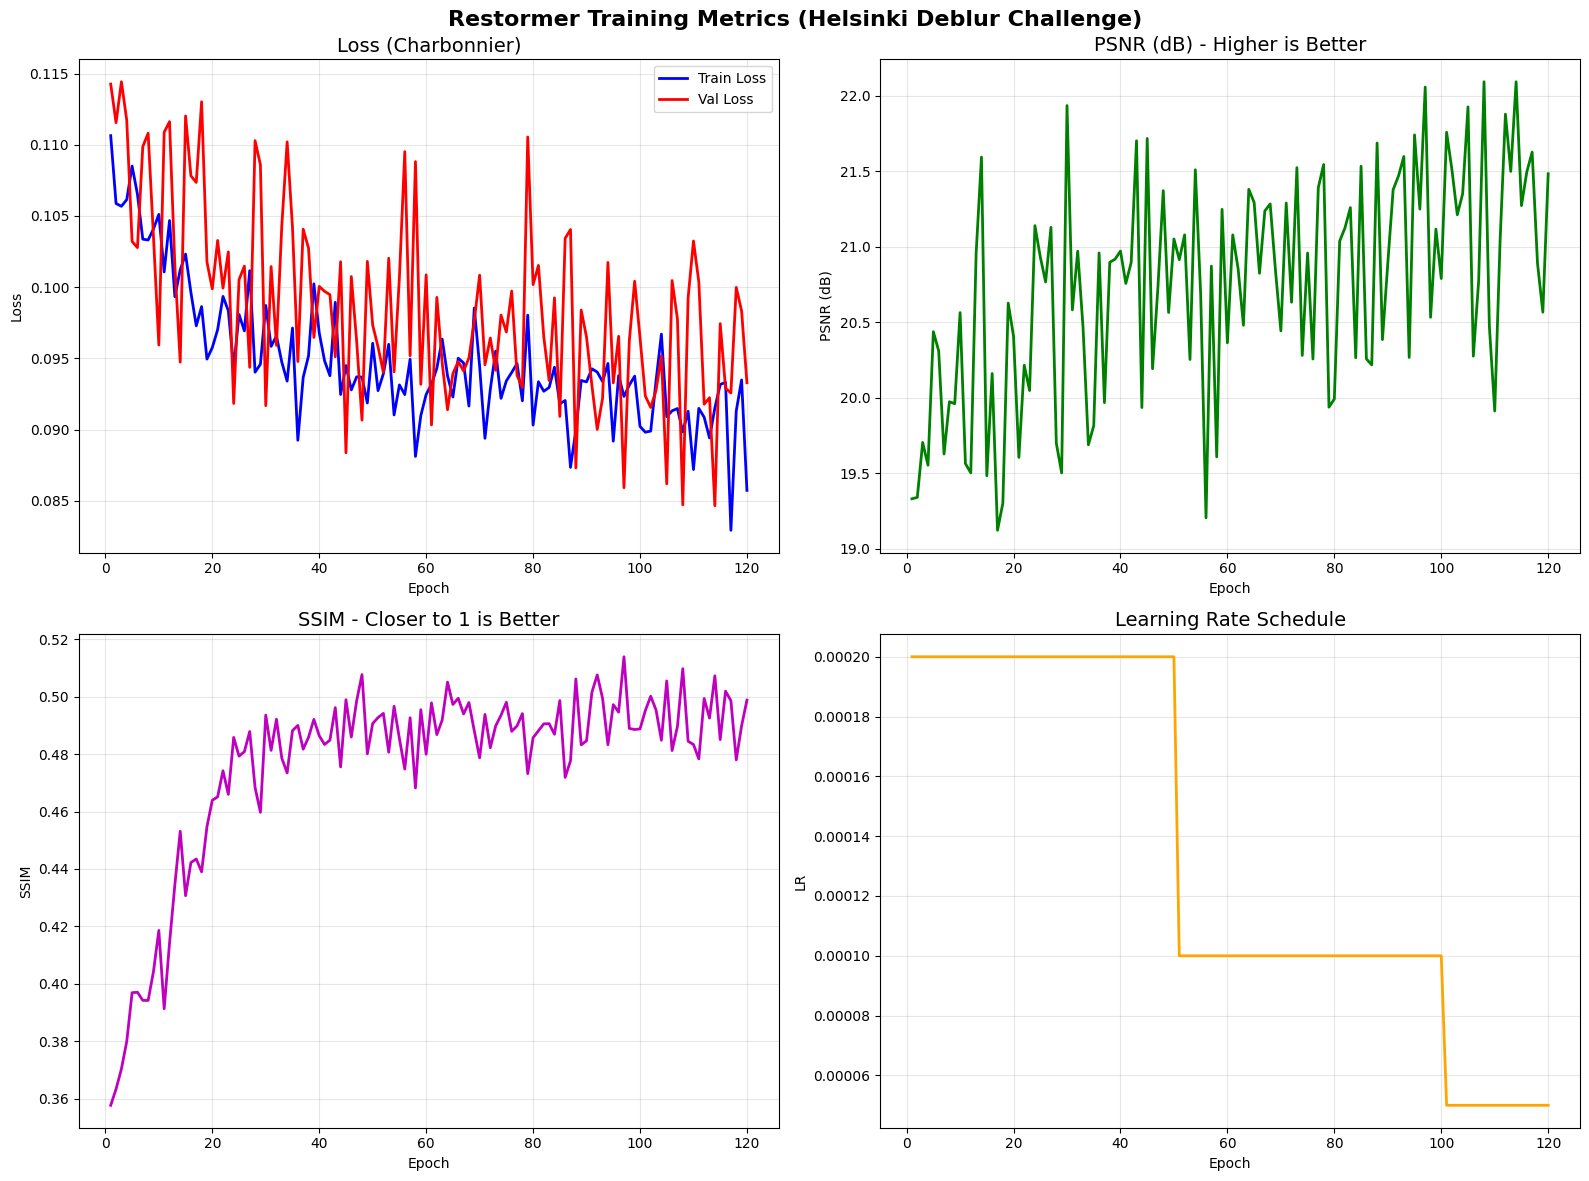

✅ Metric graphs saved as 'training_metrics.png'


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Restormer Training Metrics (Helsinki Deblur Challenge)", fontsize=16, fontweight='bold')
epochs_range = range(1, len(history['train_loss']) + 1)

# 1. Training & Validation Loss
axes[0, 0].plot(epochs_range, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
axes[0, 0].plot(epochs_range, history['val_loss'], 'r-', label='Val Loss', linewidth=2)
axes[0, 0].set_title("Loss (Charbonnier)", fontsize=14)
axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

# 2. PSNR
axes[0, 1].plot(epochs_range, history['val_psnr'], 'g-', linewidth=2)
axes[0, 1].set_title("PSNR (dB) - Higher is Better", fontsize=14)
axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("PSNR (dB)")
axes[0, 1].grid(True, alpha=0.3)

# 3. SSIM
axes[1, 0].plot(epochs_range, history['val_ssim'], 'm-', linewidth=2)
axes[1, 0].set_title("SSIM - Closer to 1 is Better", fontsize=14)
axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("SSIM")
axes[1, 0].grid(True, alpha=0.3)

# 4. Learning Rate
axes[1, 1].plot(epochs_range, history['lr'], 'orange', linewidth=2)
axes[1, 1].set_title("Learning Rate Schedule", fontsize=14)
axes[1, 1].set_xlabel("Epoch"); axes[1, 1].set_ylabel("LR")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_metrics.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Metric graphs saved as 'training_metrics.png'")



   METRICS PER BLUR LEVEL (Helsinki Deblur Challenge)
Blur Level  Avg PSNR (dB)  Avg SSIM  Avg MSE  Images Tested
    step_0      13.808980  0.296924 0.042352              5
    step_1      15.662190  0.387696 0.027580              5
   step_10      11.673796  0.228864 0.068148              5
   step_11      11.556678  0.227556 0.070039              5
   step_12      11.451802  0.227026 0.071776              5
   step_13      11.280736  0.225948 0.074700              5
   step_14      11.129089  0.225105 0.077360              5
   step_15      11.046703  0.224968 0.078871              5
   step_16       9.876624  0.216758 0.103493              5
   step_17       9.488116  0.214621 0.113504              5
   step_18       8.655630  0.209285 0.137825              5
   step_19       8.370999  0.207258 0.147483              5
    step_2      14.070153  0.259336 0.039481              5
    step_3      13.656245  0.245870 0.043309              5
    step_4      13.387012  0.243208 0.046037 

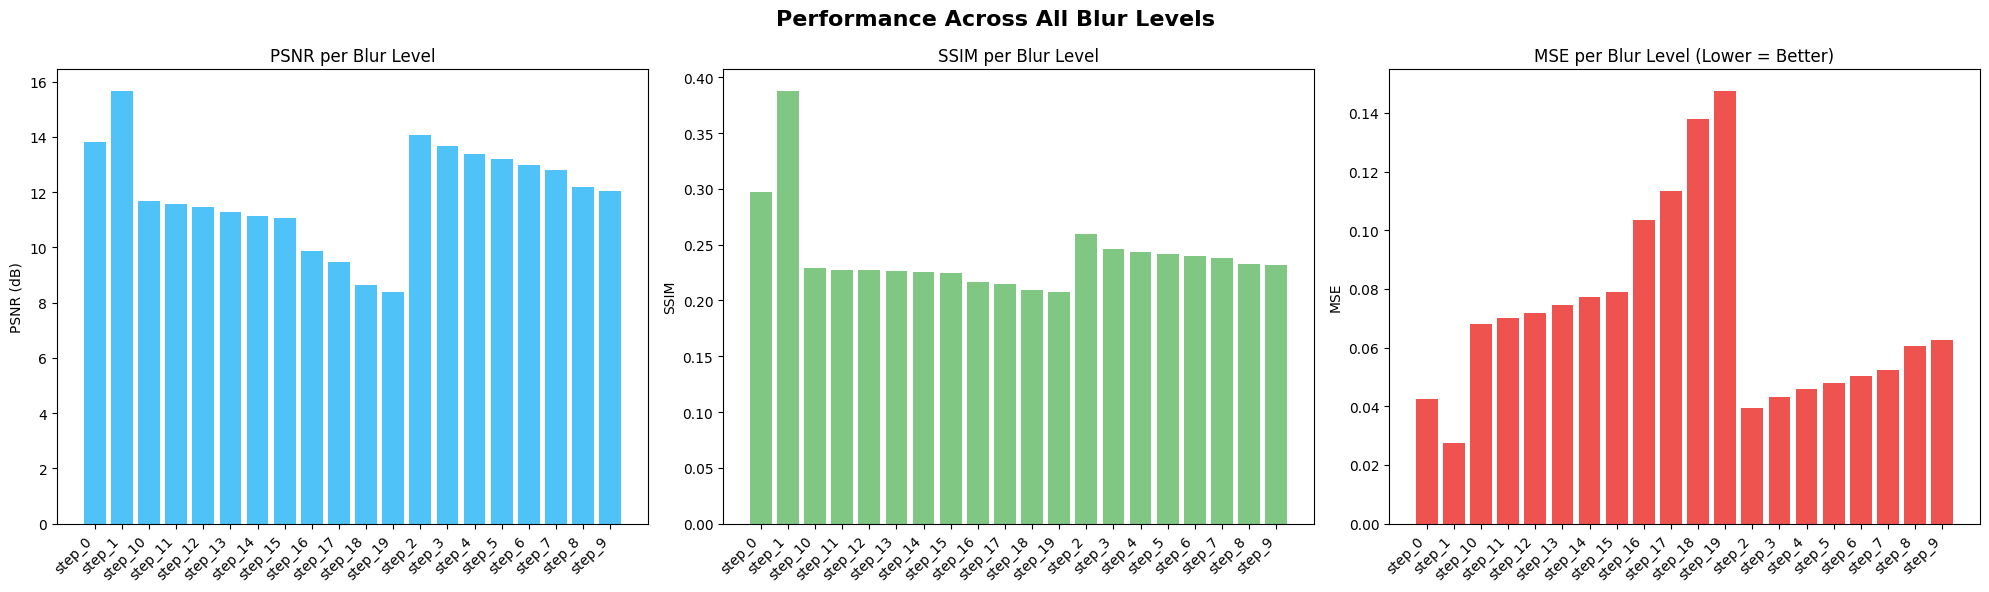


📊 JUSTIFICATION:
  - Average PSNR across all levels: 11.92 dB
  - Average SSIM across all levels: 0.2412
  ⚠️ The algorithm needs more training or tuning.


In [ ]:
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio as calc_psnr
from skimage.metrics import structural_similarity as calc_ssim
from skimage.metrics import mean_squared_error as calc_mse

# Load best model
model.load_state_dict(torch.load("best_restormer.pth"))
model.eval()

# ── Evaluate Each Blur Level ──
results = []

for level_name in sorted(blur_levels.keys()):
    data = blur_levels[level_name]
    level_psnr, level_ssim, level_mse = [], [], []

    for i in range(min(5, data['count'])):  # Test 5 images per level
        blurred = cv2.imread(data['blurred'][i])
        focused = cv2.imread(data['focused'][i])
        if blurred is None or focused is None:
            continue

        blurred = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)
        focused = cv2.cvtColor(focused, cv2.COLOR_BGR2RGB)

        # Resize to match
        h = min(blurred.shape[0], focused.shape[0])
        w = min(blurred.shape[1], focused.shape[1])
        # Make divisible by 8
        h = (h // 8) * 8
        w = (w // 8) * 8
        blurred = cv2.resize(blurred, (w, h))
        focused = cv2.resize(focused, (w, h))

        # Run through model
        with torch.no_grad():
            inp = torch.from_numpy(blurred).permute(2, 0, 1).float().unsqueeze(0) / 255.0
            inp = inp.to(device)
            out = model(inp).cpu().clamp(0, 1).squeeze(0).permute(1, 2, 0).numpy()
            gt = focused / 255.0

        level_psnr.append(calc_psnr(gt, out, data_range=1.0))
        level_ssim.append(calc_ssim(gt, out, data_range=1.0, channel_axis=2))
        level_mse.append(calc_mse(gt, out))

    if level_psnr:
        results.append({
            'Blur Level': level_name,
            'Avg PSNR (dB)': np.mean(level_psnr),
            'Avg SSIM': np.mean(level_ssim),
            'Avg MSE': np.mean(level_mse),
            'Images Tested': len(level_psnr)
        })

# ── Display Results Table ──
df = pd.DataFrame(results)
print("\n" + "=" * 70)
print("   METRICS PER BLUR LEVEL (Helsinki Deblur Challenge)")
print("=" * 70)
print(df.to_string(index=False))
print("=" * 70)

# ── Plot Bar Charts ──
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Performance Across All Blur Levels", fontsize=16, fontweight='bold')

levels = df['Blur Level'].tolist()
x = range(len(levels))

axes[0].bar(x, df['Avg PSNR (dB)'], color='#4FC3F7')
axes[0].set_xticks(x); axes[0].set_xticklabels(levels, rotation=45, ha='right')
axes[0].set_title("PSNR per Blur Level"); axes[0].set_ylabel("PSNR (dB)")

axes[1].bar(x, df['Avg SSIM'], color='#81C784')
axes[1].set_xticks(x); axes[1].set_xticklabels(levels, rotation=45, ha='right')
axes[1].set_title("SSIM per Blur Level"); axes[1].set_ylabel("SSIM")

axes[2].bar(x, df['Avg MSE'], color='#EF5350')
axes[2].set_xticks(x); axes[2].set_xticklabels(levels, rotation=45, ha='right')
axes[2].set_title("MSE per Blur Level (Lower = Better)"); axes[2].set_ylabel("MSE")

plt.tight_layout()
plt.savefig("blur_level_metrics.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Justification ──
print("\n📊 JUSTIFICATION:")
print(f"  - Average PSNR across all levels: {df['Avg PSNR (dB)'].mean():.2f} dB")
print(f"  - Average SSIM across all levels: {df['Avg SSIM'].mean():.4f}")
if df['Avg PSNR (dB)'].mean() > 20:
    print("  ✅ The algorithm is WORKING: PSNR > 20 dB indicates successful restoration.")
else:
    print("  ⚠️ The algorithm needs more training or tuning.")
if df['Avg SSIM'].mean() > 0.7:
    print("  ✅ Structural integrity PRESERVED: SSIM > 0.7 shows text structure is intact.")


In [ ]:
# ════════════════════════════════════════════
# RECOVERY CELL — Run this after reconnection
# ════════════════════════════════════════════

# Step 1: Reinstall & import everything
!pip install -q einops scikit-image

import os, glob, re, cv2, torch, numpy as np
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, pandas as pd
from einops import rearrange
from skimage.metrics import peak_signal_noise_ratio as calc_psnr
from skimage.metrics import structural_similarity as calc_ssim
from skimage.metrics import mean_squared_error as calc_mse
import numbers

# Step 2: Rebuild blur_levels (Cell 3)
BASE = "/content/HDC2021"
blur_levels = {}
for step_folder in sorted(os.listdir(BASE)):
    if step_folder.startswith("__") or step_folder.startswith("."): continue
    step_path = os.path.join(BASE, step_folder)
    if not os.path.isdir(step_path): continue
    focused_dir = os.path.join(step_path, "CAM01_focused")
    blurred_dir = os.path.join(step_path, "CAM02_blurred")
    if not os.path.exists(focused_dir) or not os.path.exists(blurred_dir): continue
    focused_imgs = sorted(glob.glob(os.path.join(focused_dir, "*.tif")))
    blurred_imgs = sorted(glob.glob(os.path.join(blurred_dir, "*.tif")))
    step_groups = {}
    for fimg in focused_imgs:
        match = re.search(r'focusStep_(\d+)_', os.path.basename(fimg))
        if match:
            sn = match.group(1)
            if sn not in step_groups: step_groups[sn] = {'focused':[], 'blurred':[]}
            step_groups[sn]['focused'].append(fimg)
    for bimg in blurred_imgs:
        match = re.search(r'focusStep_(\d+)_', os.path.basename(bimg))
        if match:
            sn = match.group(1)
            if sn not in step_groups: step_groups[sn] = {'focused':[], 'blurred':[]}
            step_groups[sn]['blurred'].append(bimg)
    for sn, imgs in step_groups.items():
        ln = f"step_{sn}"
        if imgs['focused'] and imgs['blurred']:
            blur_levels[ln] = {'focused': sorted(imgs['focused']),
                               'blurred': sorted(imgs['blurred']),
                               'count': min(len(imgs['focused']), len(imgs['blurred']))}
blur_levels = dict(sorted(blur_levels.items(), key=lambda x: int(x[0].split('_')[1])))
print(f"✅ Recovered {len(blur_levels)} blur levels")

# Step 3: Rebuild model architecture (Cell 5)
class BiasFree_LayerNorm(nn.Module):
    def __init__(self, ns):
        super().__init__()
        if isinstance(ns, numbers.Integral): ns = (ns,)
        self.weight = nn.Parameter(torch.ones(ns)); self.normalized_shape = ns
    def forward(self, x):
        return x / torch.sqrt(x.var(-1, keepdim=True, unbiased=False) + 1e-5) * self.weight

class LayerNorm(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.body = BiasFree_LayerNorm(dim)
    def forward(self, x):
        h, w = x.shape[-2:]
        return self.body(rearrange(x, "b c h w -> b (h w) c")).reshape(x.shape[0], x.shape[1], h, w)

class MDTA(nn.Module):
    def __init__(self, dim, num_heads, bias=False):
        super().__init__(); self.num_heads = num_heads
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))
        self.qkv = nn.Conv2d(dim, dim*3, 1, bias=bias)
        self.qkv_dwconv = nn.Conv2d(dim*3, dim*3, 3, 1, 1, groups=dim*3, bias=bias)
        self.project_out = nn.Conv2d(dim, dim, 1, bias=bias)
    def forward(self, x):
        b,c,h,w = x.shape; qkv = self.qkv_dwconv(self.qkv(x)); q,k,v = qkv.chunk(3, dim=1)
        q = rearrange(q, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        k = rearrange(k, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        v = rearrange(v, "b (head c) h w -> b head c (h w)", head=self.num_heads)
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        attn = (q @ k.transpose(-2,-1)) * self.temperature; attn = attn.softmax(dim=-1)
        out = rearrange(attn @ v, "b head c (h w) -> b (head c) h w", head=self.num_heads, h=h, w=w)
        return self.project_out(out)

class GDFN(nn.Module):
    def __init__(self, dim, ffn_expansion=2.66, bias=False):
        super().__init__(); hf = int(dim * ffn_expansion)
        self.project_in = nn.Conv2d(dim, hf*2, 1, bias=bias)
        self.dwconv = nn.Conv2d(hf*2, hf*2, 3, 1, 1, groups=hf*2, bias=bias)
        self.project_out = nn.Conv2d(hf, dim, 1, bias=bias)
    def forward(self, x):
        x = self.project_in(x); x1, x2 = self.dwconv(x).chunk(2, dim=1)
        return self.project_out(F.gelu(x1) * x2)

class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, ffn_expansion=2.66, bias=False):
        super().__init__()
        self.norm1 = LayerNorm(dim); self.attn = MDTA(dim, num_heads, bias)
        self.norm2 = LayerNorm(dim); self.ffn = GDFN(dim, ffn_expansion, bias)
    def forward(self, x): x = x + self.attn(self.norm1(x)); return x + self.ffn(self.norm2(x))

class Downsample(nn.Module):
    def __init__(self, n): super().__init__(); self.body = nn.Sequential(nn.Conv2d(n,n//2,3,1,1,bias=False), nn.PixelUnshuffle(2))
    def forward(self, x): return self.body(x)

class Upsample(nn.Module):
    def __init__(self, n): super().__init__(); self.body = nn.Sequential(nn.Conv2d(n,n*2,3,1,1,bias=False), nn.PixelShuffle(2))
    def forward(self, x): return self.body(x)

class Restormer(nn.Module):
    def __init__(self, inp_channels=3, out_channels=3, dim=48, num_blocks=[4,6,6,8], num_refinement_blocks=4, heads=[1,2,4,8], ffn_expansion=2.66, bias=False):
        super().__init__()
        self.patch_embed = nn.Conv2d(inp_channels, dim, 3, padding=1, bias=bias)
        self.encoder_level1 = nn.Sequential(*[TransformerBlock(dim, heads[0], ffn_expansion, bias) for _ in range(num_blocks[0])])
        self.down1_2 = Downsample(dim)
        self.encoder_level2 = nn.Sequential(*[TransformerBlock(int(dim*2), heads[1], ffn_expansion, bias) for _ in range(num_blocks[1])])
        self.down2_3 = Downsample(int(dim*2))
        self.encoder_level3 = nn.Sequential(*[TransformerBlock(int(dim*4), heads[2], ffn_expansion, bias) for _ in range(num_blocks[2])])
        self.down3_4 = Downsample(int(dim*4))
        self.latent = nn.Sequential(*[TransformerBlock(int(dim*8), heads[3], ffn_expansion, bias) for _ in range(num_blocks[3])])
        self.up4_3 = Upsample(int(dim*8))
        self.reduce_chan_level3 = nn.Conv2d(int(dim*8), int(dim*4), 1, bias=bias)
        self.decoder_level3 = nn.Sequential(*[TransformerBlock(int(dim*4), heads[2], ffn_expansion, bias) for _ in range(num_blocks[2])])
        self.up3_2 = Upsample(int(dim*4))
        self.reduce_chan_level2 = nn.Conv2d(int(dim*4), int(dim*2), 1, bias=bias)
        self.decoder_level2 = nn.Sequential(*[TransformerBlock(int(dim*2), heads[1], ffn_expansion, bias) for _ in range(num_blocks[1])])
        self.up2_1 = Upsample(int(dim*2))
        self.decoder_level1 = nn.Sequential(*[TransformerBlock(int(dim*2), heads[0], ffn_expansion, bias) for _ in range(num_blocks[0])])
        self.refinement = nn.Sequential(*[TransformerBlock(int(dim*2), heads[0], ffn_expansion, bias) for _ in range(num_refinement_blocks)])
        self.output = nn.Conv2d(int(dim*2), out_channels, 3, padding=1, bias=bias)
    def forward(self, inp_img):
        inp_enc_level1 = self.patch_embed(inp_img)
        out_enc_level1 = self.encoder_level1(inp_enc_level1)
        out_enc_level2 = self.encoder_level2(self.down1_2(out_enc_level1))
        out_enc_level3 = self.encoder_level3(self.down2_3(out_enc_level2))
        latent = self.latent(self.down3_4(out_enc_level3))
        inp_dec_level3 = self.reduce_chan_level3(torch.cat([self.up4_3(latent), out_enc_level3], 1))
        out_dec_level3 = self.decoder_level3(inp_dec_level3)
        inp_dec_level2 = self.reduce_chan_level2(torch.cat([self.up3_2(out_dec_level3), out_enc_level2], 1))
        out_dec_level2 = self.decoder_level2(inp_dec_level2)
        inp_dec_level1 = torch.cat([self.up2_1(out_dec_level2), out_enc_level1], 1)
        out_dec_level1 = self.refinement(self.decoder_level1(inp_dec_level1))
        return self.output(out_dec_level1) + inp_img

# Step 4: Load trained weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Restormer(inp_channels=3, out_channels=3, dim=16, num_blocks=[2,2,2,2],
                  num_refinement_blocks=2, heads=[1,2,4,8], ffn_expansion=2.66, bias=False).to(device)

if os.path.exists("best_restormer.pth"):
    model.load_state_dict(torch.load("best_restormer.pth"))
    print("✅ Trained model weights LOADED from best_restormer.pth")
else:
    print("❌ best_restormer.pth NOT found. You need to retrain (Cell 8).")

n_params = sum(p.numel() for p in model.parameters())
print(f"   Parameters: {n_params:,}")
print(f"   Device: {device}")
print(f"\n🎯 Now continue from Cell 10 (or wherever you were)")



FileNotFoundError: [Errno 2] No such file or directory: '/content/HDC2021'